In [ ]:
# plot the PA change of a target

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import dates as mdates
import astropy.units as u
from astropy.time import Time
from astropy.coordinates import SkyCoord
from astroplan import Observer, FixedTarget
from astroplan.plots import plot_parallactic
from datetime import datetime
from zoneinfo import ZoneInfo

In [ ]:
# 1. Define your location (e.g., Zurich) and your target (e.g., Orion Nebula)

lat_mgio = 32.7016*u.deg
lon_mgio = -109.8719*u.deg
el_mgio = 3220.8*u.m
target_name = "AB Aur"
tucson_tz = ZoneInfo("America/Phoenix")

observer = Observer(latitude=lat_mgio, longitude=lon_mgio, elevation=el_mgio, name="MGIO")
coordinates = SkyCoord.from_name(target_name)
target = FixedTarget(coord=coordinates, name=target_name)

def plot_pa(target, observer, midnight_time, sunset, sunrise, tz=tucson_tz):
    """Plot parallactic angle around midnight with sunset/sunrise markers."""
    local = midnight_time.to_datetime(timezone=tz)

    # display 16 hrs around midnight
    times = midnight_time + np.linspace(-8, 8, 100) * u.hour

    fig, ax = plt.subplots(figsize=(10, 6))
    
    plot_parallactic(target, observer, times, ax=ax)

    # plot_parallactic uses radians; convert to degrees
    for line in ax.get_lines():
        line.set_ydata(np.degrees(line.get_ydata()))
    ax.relim()
    ax.autoscale_view(scalex=False)
    ax.set_ylabel("Parallactic Angle [deg]")

    # Top axis: same UTC data coords, labeled in local time
    ax_local = ax.secondary_xaxis("top")
    ax_local.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=tz))
    ax_local.set_xlabel(f"Local time ({local:%Z})")

    ax.axvline(sunset.datetime.replace(tzinfo=None), color='k', linestyle='--', alpha=0.5)
    ax.axvline(sunrise.datetime.replace(tzinfo=None), color='k', linestyle='--', alpha=0.5)
    ax.set_title(f"PA for {target.name} on starting night {local:%Y-%m-%d %Z}\n(dashed: sunset/sunrise)")
    ax.xaxis.set_major_locator(mdates.HourLocator())
    ax.grid(True, which="major", axis="both")

    plt.tight_layout()
    #plt.show()
    plt.savefig(f"pa_for_{target.name}_on_{local:%Y-%m-%d}.png")
    return fig, ax





In [32]:


nights = [
    {
        "label": "2026-09-21",
        "midnight": Time(datetime(2026, 9, 21, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2026, 9, 21, 18, 21, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2026, 9, 22, 6, 12, 0, tzinfo=tucson_tz)),
    },
    {
        "label": "2026-09-28",
        "midnight": Time(datetime(2026, 9, 28, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2026, 9, 28, 18, 12, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2026, 9, 29, 6, 16, 0, tzinfo=tucson_tz)),
    },
    {
        "label": "2026-10-08",
        "midnight": Time(datetime(2026, 10, 8, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2026, 10, 8, 17, 59, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2026, 10, 9, 6, 23, 0, tzinfo=tucson_tz)),
    },
        {
        "label": "2026-10-13",
        "midnight": Time(datetime(2026, 10, 13, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2026, 10, 13, 17, 53, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2026, 10, 14, 6, 26, 0, tzinfo=tucson_tz)),
    },
        {
        "label": "2026-10-25",
        "midnight": Time(datetime(2026, 10, 25, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2026, 10, 25, 17, 39, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2026, 10, 26, 6, 35, 0, tzinfo=tucson_tz)),
    },
        {
        "label": "2026-11-01",
        "midnight": Time(datetime(2026, 11, 1, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2026, 11, 1, 17, 33, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2026, 11, 2, 6, 41, 0, tzinfo=tucson_tz)),
    },
        {
        "label": "2026-11-14",
        "midnight": Time(datetime(2026, 11, 14, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2026, 11, 14, 17, 23, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2026, 11, 15, 6, 52, 0, tzinfo=tucson_tz)),
    },
        {
        "label": "2026-11-22",
        "midnight": Time(datetime(2026, 11, 22, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2026, 11, 22, 17, 20, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2026, 11, 23, 7, 0, 0, tzinfo=tucson_tz)),
    },
        {
        "label": "2026-11-29",
        "midnight": Time(datetime(2026, 11, 29, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2026, 11, 29, 17, 18, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2026, 11, 30, 7, 6, 0, tzinfo=tucson_tz)),
    },
        {
        "label": "2026-12-04",
        "midnight": Time(datetime(2026, 12, 4, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2026, 12, 4, 17, 18, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2026, 12, 5, 7, 10, 0, tzinfo=tucson_tz)),
    },
        {
        "label": "2026-12-17",
        "midnight": Time(datetime(2026, 12, 17, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2026, 12, 17, 17, 21, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2026, 12, 18, 7, 19, 0, tzinfo=tucson_tz)),
    },
        {
        "label": "2027-01-04",
        "midnight": Time(datetime(2027, 1, 4, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2027, 1, 4, 17, 31, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2027, 1, 5, 7, 25, 0, tzinfo=tucson_tz)),
    },
        {
        "label": "2026-01-21",
        "midnight": Time(datetime(2027, 1, 21, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2027, 1, 21, 17, 46, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2027, 1, 22, 7, 23, 0, tzinfo=tucson_tz)),
    },
        {
        "label": "2027-01-31",
        "midnight": Time(datetime(2027, 1, 31, 23, 59, 0, tzinfo=tucson_tz)),
        "sunset": Time(datetime(2027, 1, 31, 17, 55, 0, tzinfo=tucson_tz)),
        "sunrise": Time(datetime(2027, 2, 1, 7, 18, 0, tzinfo=tucson_tz)),
    },
]

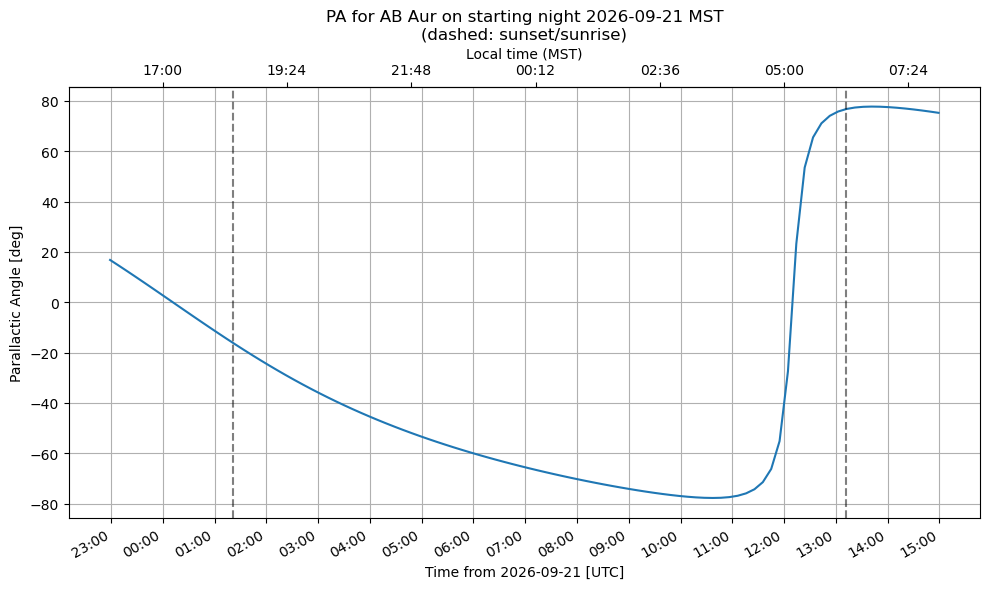

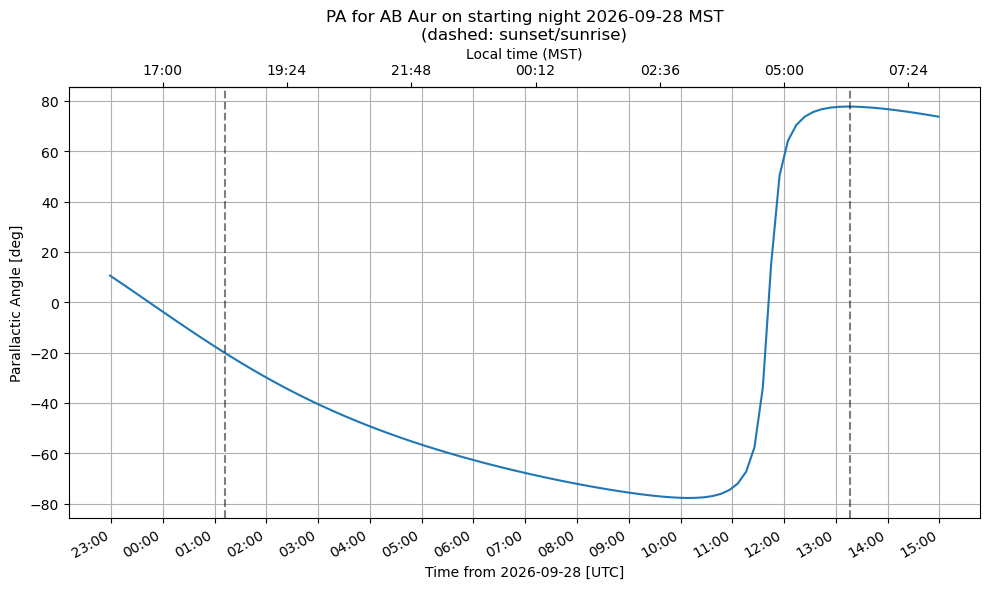

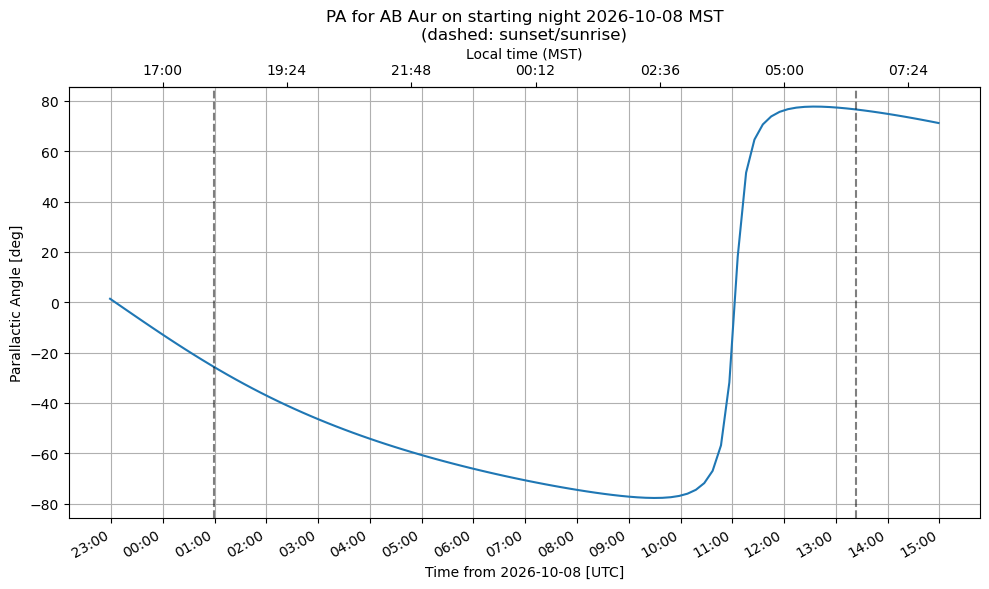

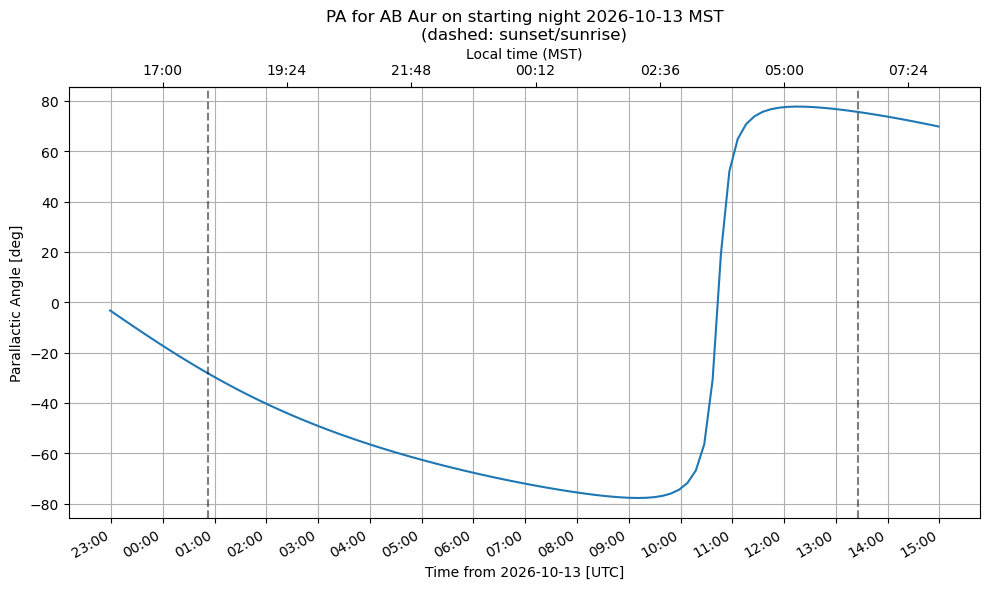

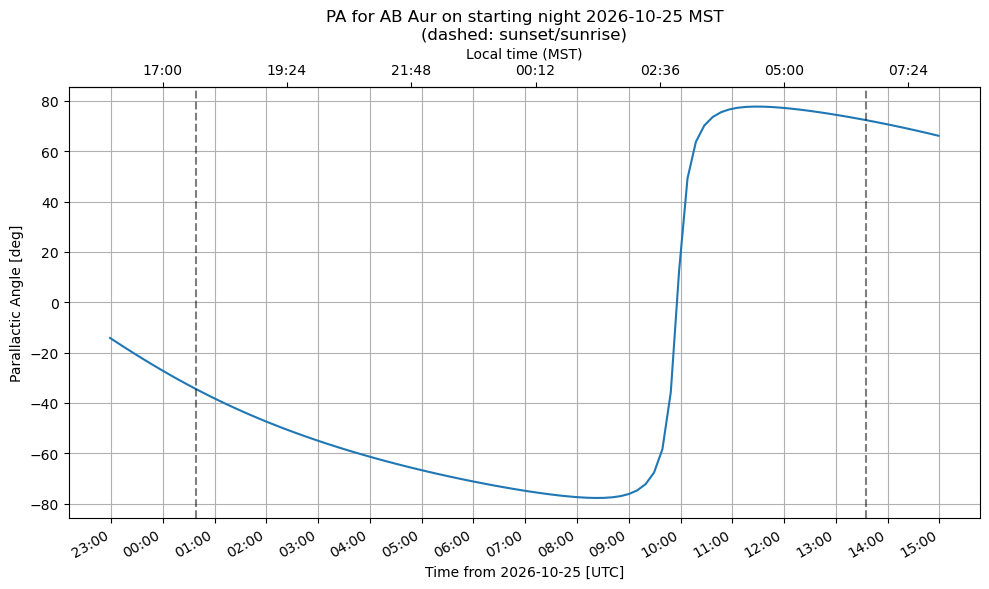

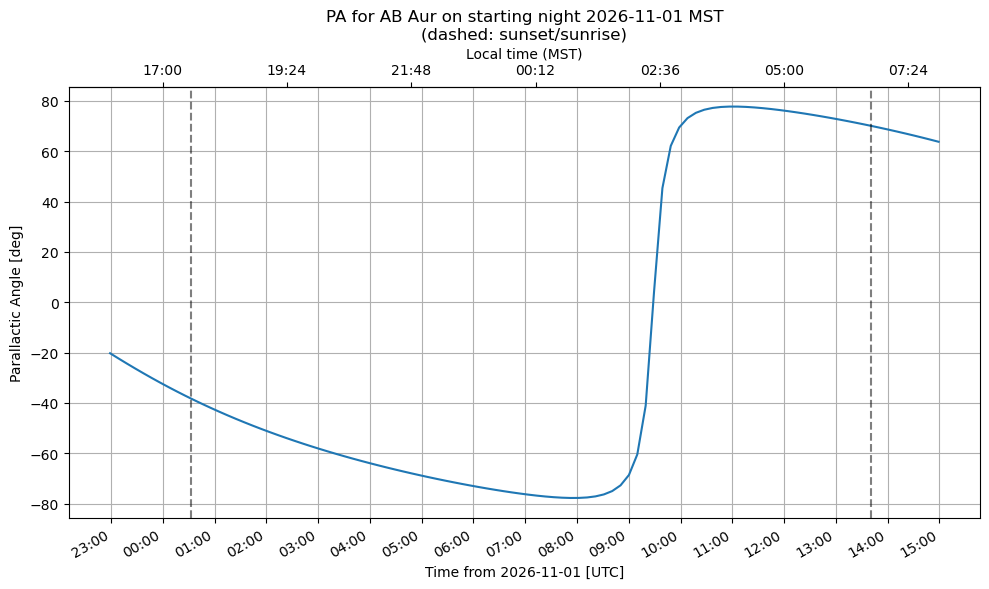

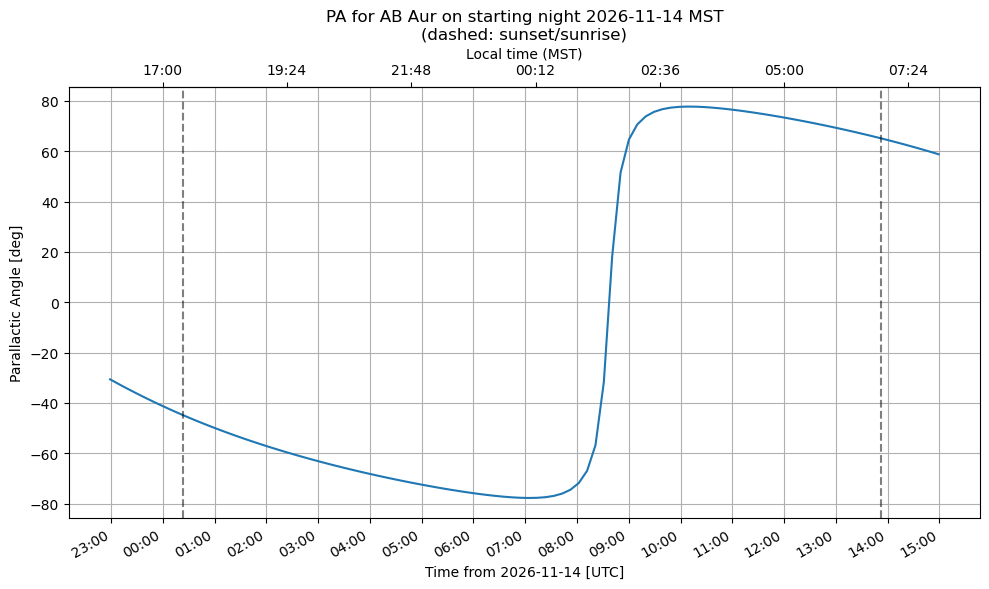

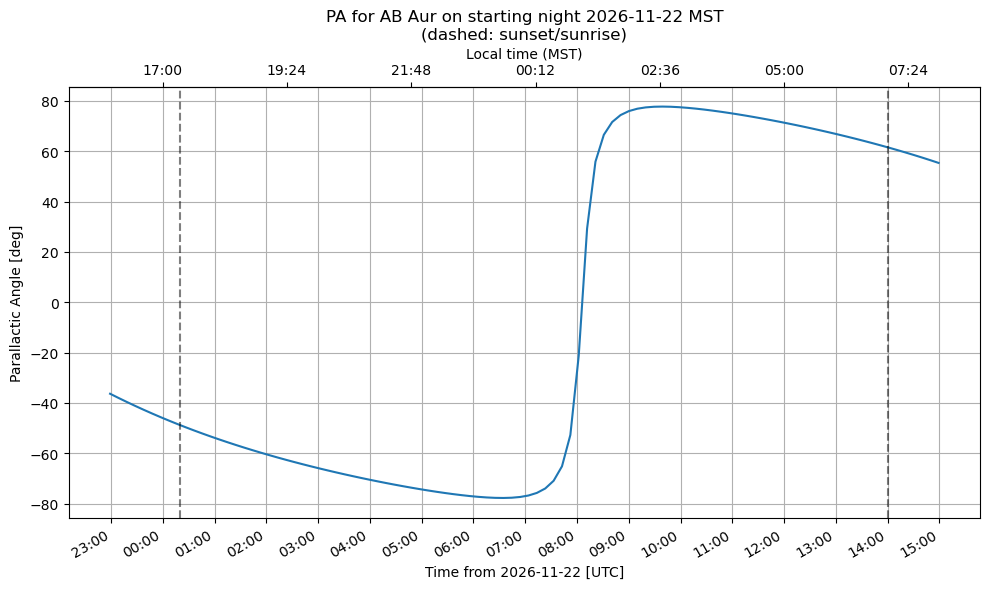

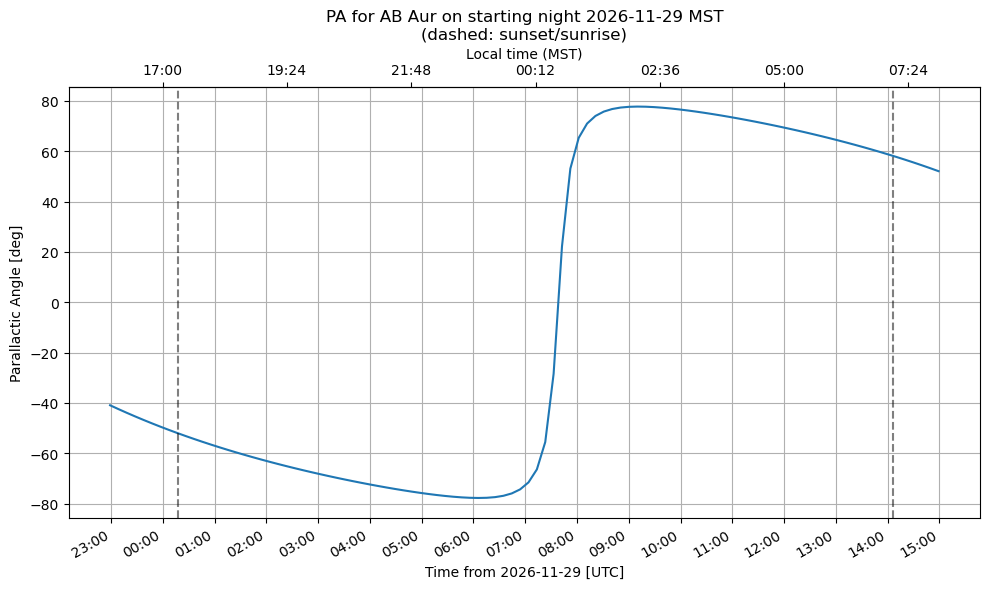

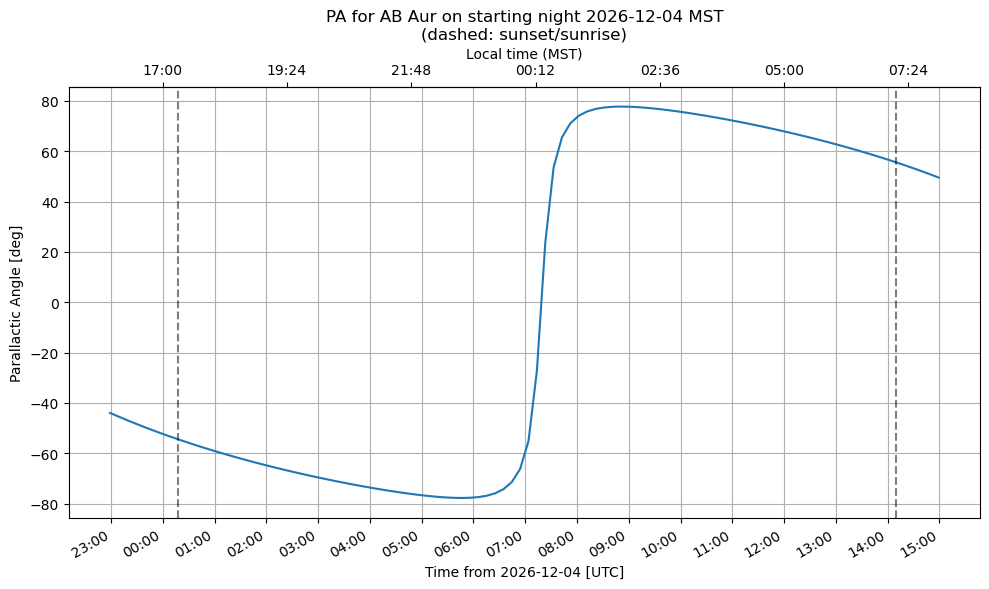

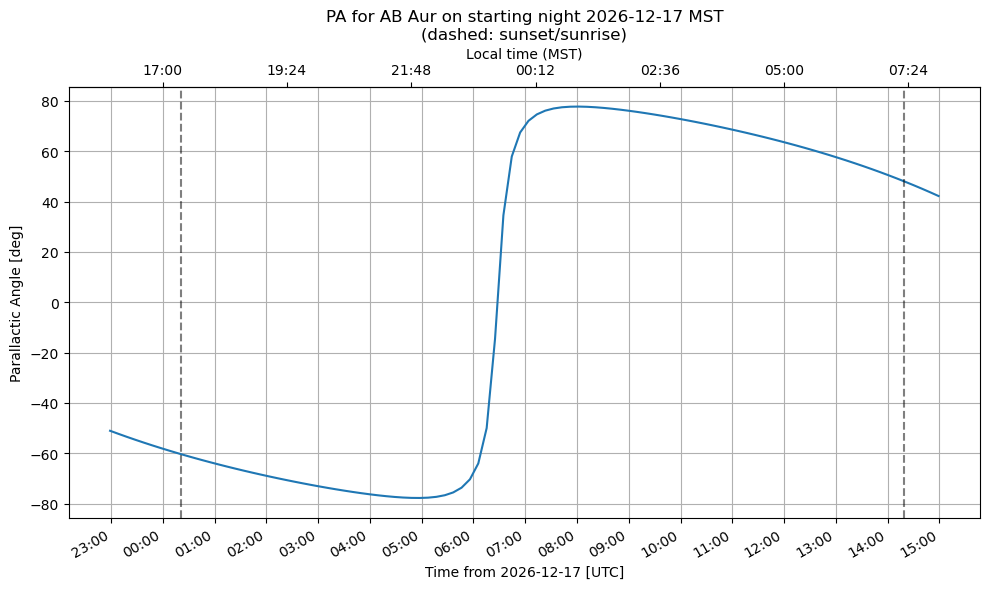

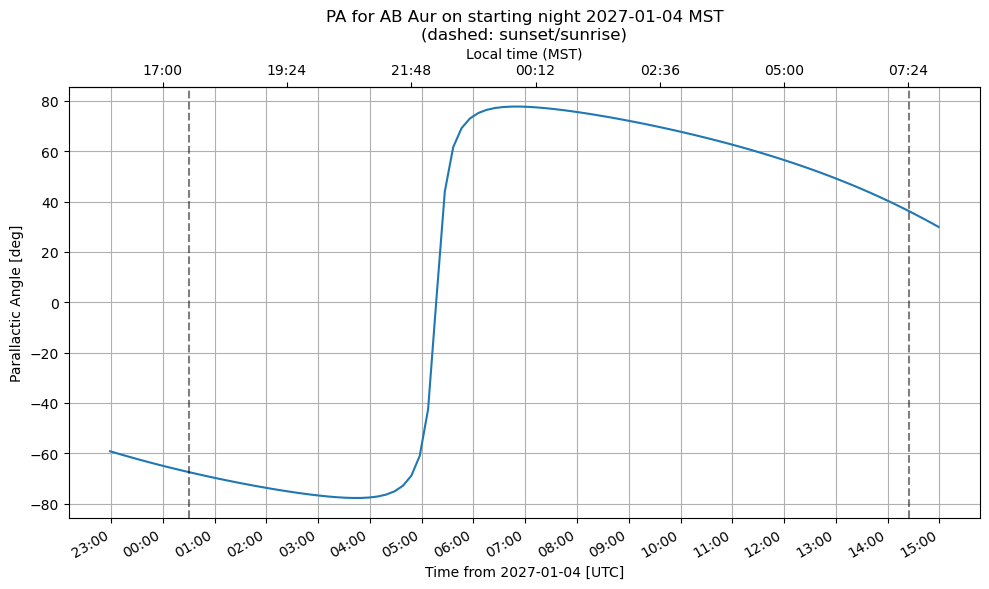

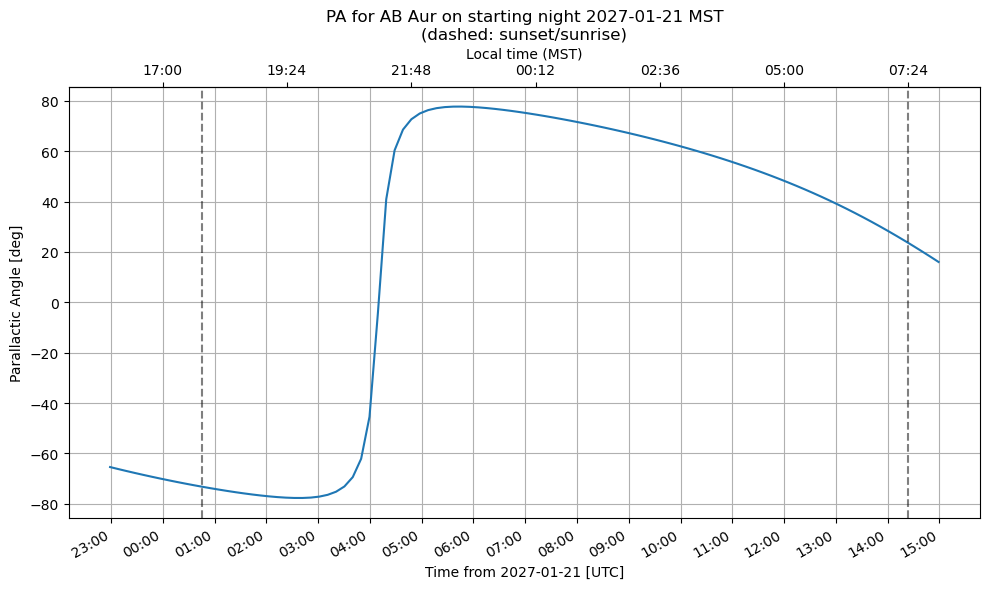

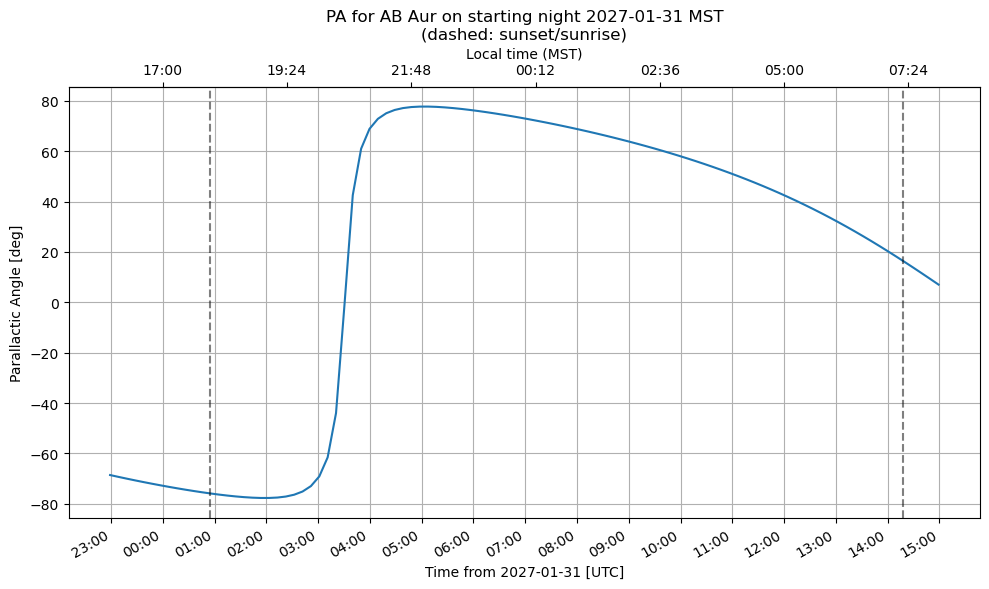

In [33]:
for night in nights:
    plot_pa(target, observer, night["midnight"], night["sunset"], night["sunrise"])